Importing libraries

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('../data/raw/European_Bank.csv')

Analysing the given data

In [4]:
df.head()

,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [5]:
df.describe()

,Year,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.0,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,2025.0,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,0.0,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,2025.0,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2025.0,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,2025.0,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,2025.0,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,2025.0,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [6]:
df.shape

(10000, 14)

In [7]:
df.isnull().sum()

Year               0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.columns

Index(['Year', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender',
       'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='str')

## 1. Data Quality Assessment

In this section, we examine the dataset for missing values, duplicate records, inconsistent data types, and invalid values.

In [10]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Count": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})

missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

,Missing Count,Missing Percentage
Year,0,0.0
CustomerId,0,0.0
Surname,0,0.0
CreditScore,0,0.0
Geography,0,0.0
Gender,0,0.0
Age,0,0.0
Tenure,0,0.0
Balance,0,0.0
NumOfProducts,0,0.0


In [11]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


Number of unique values in Columns

In [12]:
df.nunique().sort_values(ascending=False)

CustomerId         10000
EstimatedSalary     9999
Balance             6382
Surname             2932
CreditScore          460
Age                   70
Tenure                11
NumOfProducts          4
Geography              3
Gender                 2
IsActiveMember         2
HasCrCard              2
Exited                 2
Year                   1
dtype: int64

Checking Categorical Column

In [13]:
categorical_columns = df.select_dtypes(
    include=["str", "category"]
).columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))


Surname:
Surname
Smith        32
Scott        29
Martin       29
Walker       28
Brown        26
             ..
Salinas       1
Cleveland     1
Kashiwagi     1
Aldridge      1
Burbidge      1
Name: count, Length: 2932, dtype: int64

Geography:
Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

Gender:
Gender
Male      5457
Female    4543
Name: count, dtype: int64


checking numerical column

In [14]:
df.select_dtypes(include=np.number).describe().T

,count,mean,std,min,25%,50%,75%,max
Year,10000.0,2.025000e+03,0.000000,2025.00,2025.00,2.025000e+03,2.025000e+03,2025.00
CustomerId,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00
CreditScore,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00
Age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00
Tenure,10000.0,5.012800e+00,2.892174,0.00,3.00,5.000000e+00,7.000000e+00,10.00
Balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09
NumOfProducts,10000.0,1.530200e+00,0.581654,1.00,1.00,1.000000e+00,2.000000e+00,4.00
HasCrCard,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00
IsActiveMember,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00
EstimatedSalary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48


## 2. Data validation and consistency

In [15]:
# Check categorical values
for column in ["Geography", "Gender"]:
    print(f"\n{column}:")
    print(df[column].value_counts())

# Check binary columns
binary_columns = ["HasCrCard", "IsActiveMember", "Exited"]

for column in binary_columns:
    print(f"\n{column}:")
    print(df[column].value_counts())


Geography:
Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

Gender:
Gender
Male      5457
Female    4543
Name: count, dtype: int64

HasCrCard:
HasCrCard
1    7055
0    2945
Name: count, dtype: int64

IsActiveMember:
IsActiveMember
1    5151
0    4849
Name: count, dtype: int64

Exited:
Exited
0    7963
1    2037
Name: count, dtype: int64


 Validate numerical ranges

In [16]:
numerical_columns = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "EstimatedSalary"
]

range_summary = pd.DataFrame({
    "Minimum": df[numerical_columns].min(),
    "Maximum": df[numerical_columns].max(),
    "Unique Values": df[numerical_columns].nunique()
})

range_summary

,Minimum,Maximum,Unique Values
CreditScore,350.00,850.00,460
Age,18.00,92.00,70
Tenure,0.00,10.00,11
Balance,0.00,250898.09,6382
NumOfProducts,1.00,4.00,4
EstimatedSalary,11.58,199992.48,9999


## 3. Check invalid records

In [17]:
validation_checks = {
    "Invalid Credit Scores": (~df["CreditScore"].between(300, 900)).sum(),
    "Invalid Ages": (df["Age"] < 18).sum(),
    "Invalid Tenure": (~df["Tenure"].between(0, 10)).sum(),
    "Invalid Product Counts": (~df["NumOfProducts"].between(1, 4)).sum(),
    "Invalid Binary Values": (
        (~df["HasCrCard"].isin([0, 1])) |
        (~df["IsActiveMember"].isin([0, 1])) |
        (~df["Exited"].isin([0, 1]))
    ).sum()
}

pd.Series(validation_checks, name="Invalid Records")

Invalid Credit Scores     0
Invalid Ages              0
Invalid Tenure            0
Invalid Product Counts    0
Invalid Binary Values     0
Name: Invalid Records, dtype: int64

##  Data Validation Findings

### 1. Categorical Values
- Geography contains three categories: France (5,014), Germany (2,509), and Spain (2,477).
- Gender contains Male (5,457) and Female (4,543).
- No missing categorical values were detected.

### 2. Binary Variables
- HasCrCard: 7,055 customers have a credit card and 2,945 do not.
- IsActiveMember: 5,151 customers are active and 4,849 are inactive.
- Exited: 7,963 customers were retained and 2,037 exited.
- All binary columns contain only 0 and 1.

### 3. Numerical Ranges
- CreditScore: 350–850.
- Age: 18–92 years.
- Tenure: 0–10 years.
- Balance: 0–250898.09.
- NumOfProducts: 1–4.
- EstimatedSalary: 11.58–199992.48.

### 4. Numerical Validation Results

The following validation checks were performed:

| Validation Check | Invalid Records |
|---|---:|
| Credit Score | 0 |
| Age | 0 |
| Tenure | 0 |
| Product Count | 0 |
| Binary Variables | 0 |

All numerical and binary fields passed the defined validation checks.

### 5. Conclusion

The dataset contains 10,000 records and 14 columns, with no missing values or duplicate rows. All categorical and binary values were found within the expected categories, and all numerical validation checks returned zero invalid records.

The dataset is suitable for proceeding to exploratory data analysis (EDA), subject to further investigation of business-specific assumptions and potential anomalies.


# 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand customer characteristics, identify patterns, examine relationships between variables, and discover factors associated with customer churn.

The analysis focuses on customer demographics, engagement, product utilization, and financial characteristics.

# Analysis 1 — Overall customer churn distribution

In [18]:
# Calculate customer retention and churn counts
churn_counts = df["Exited"].value_counts().sort_index()

# Calculate percentages
churn_percentage = df["Exited"].value_counts(normalize=True).sort_index() * 100

churn_summary = pd.DataFrame({
    "Customer Count": churn_counts,
    "Percentage": churn_percentage
})

churn_summary.index = ["Retained", "Exited"]

churn_summary

,Customer Count,Percentage
Retained,7963,79.63
Exited,2037,20.37


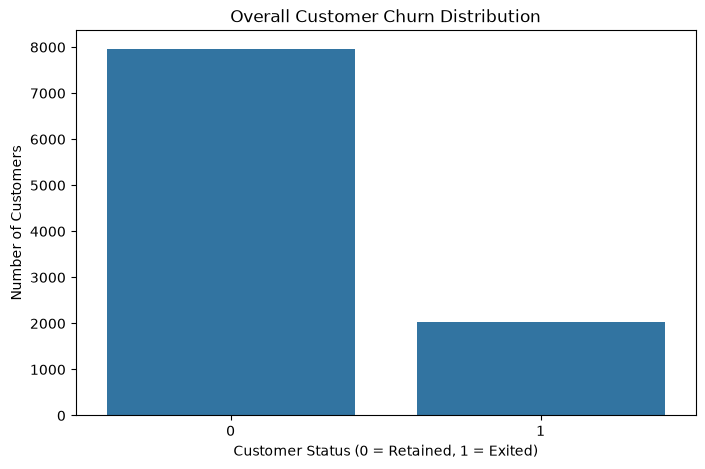

In [20]:

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Exited")

plt.title("Overall Customer Churn Distribution")
plt.xlabel("Customer Status (0 = Retained, 1 = Exited)")
plt.ylabel("Number of Customers")

plt.show()


# Analysis 2 — Customer demographics

A. Churn by geography

In [23]:

geography_churn = df.groupby("Geography")["Exited"].mean() * 100

geography_churn.sort_values(ascending=False)


Geography
Germany    32.443204
Spain      16.673395
France     16.154767
Name: Exited, dtype: float64

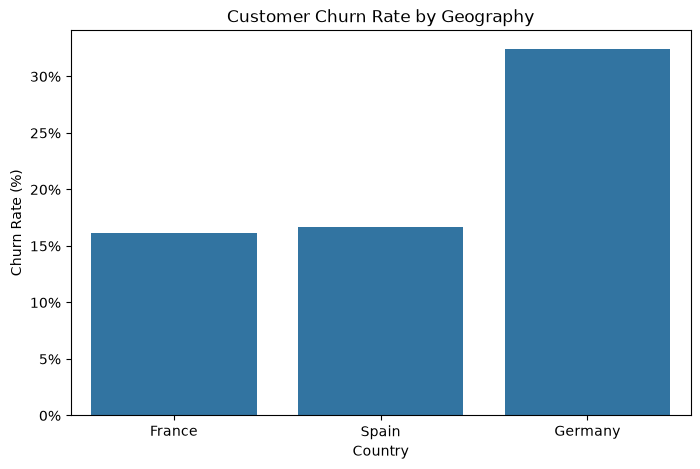

In [24]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Geography",
    y="Exited",
    errorbar=None
)

plt.title("Customer Churn Rate by Geography")
plt.xlabel("Country")
plt.ylabel("Churn Rate (%)")

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y * 100:.0f}%")
)

plt.show()


B. Churn by gender

In [26]:
gender_churn = df.groupby("Gender")["Exited"].mean() * 100

gender_churn


Gender
Female    25.071539
Male      16.455928
Name: Exited, dtype: float64

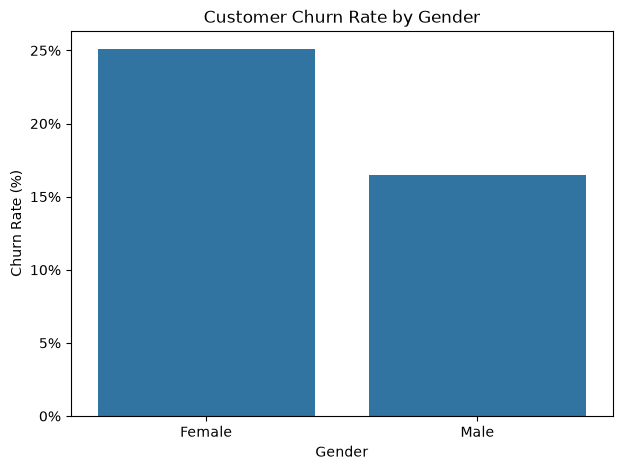

In [27]:

plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="Gender",
    y="Exited",
    errorbar=None
)

plt.title("Customer Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y * 100:.0f}%")
)

plt.show()


# Analysis 3 — Customer engagement

In [29]:
activity_churn = (
    df.groupby("IsActiveMember")["Exited"].mean() * 100
)


activity_churn.index = ["Inactive", "Active"]

activity_churn


Inactive    26.850897
Active      14.269074
Name: Exited, dtype: float64

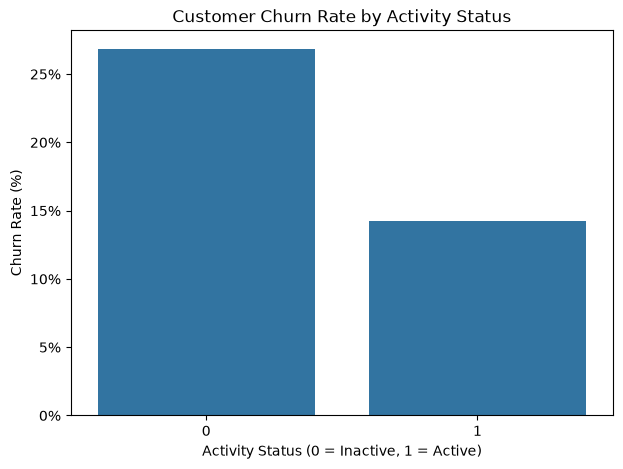

In [32]:

plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="IsActiveMember",
    y="Exited",
    errorbar=None
)

plt.title("Customer Churn Rate by Activity Status")
plt.xlabel("Activity Status (0 = Inactive, 1 = Active)")
plt.ylabel("Churn Rate (%)")

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y * 100:.0f}%")
)

plt.show()


# Analysis 4 — Product utilization

In [35]:
# Calculate customer count and churn rate for each product group
product_analysis = df.groupby("NumOfProducts").agg(
    Customer_Count=("CustomerId", "count"),
    Churn_Rate=("Exited", "mean")
)

# Convert churn rate into percentage
product_analysis["Churn_Rate"] *= 100

product_analysis


,Customer_Count,Churn_Rate
NumOfProducts,,
1,5084,27.714398
2,4590,7.581699
3,266,82.706767
4,60,100.000000


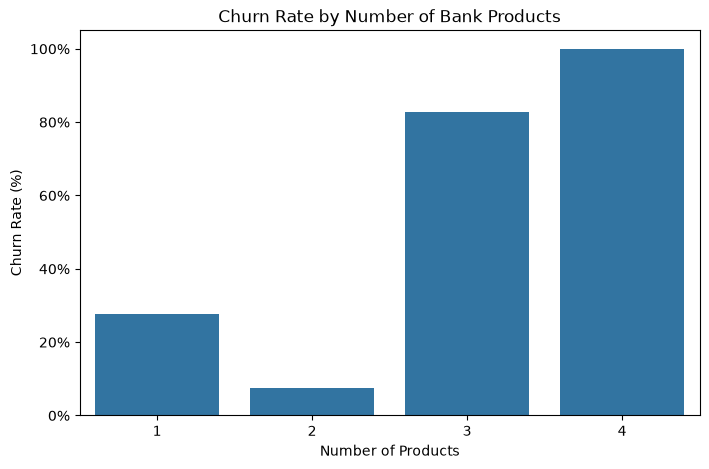

In [36]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="NumOfProducts",
    y="Exited",
    errorbar=None
)

plt.title("Churn Rate by Number of Bank Products")
plt.xlabel("Number of Products")
plt.ylabel("Churn Rate (%)")

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y * 100:.0f}%")
)

plt.show()


# Analysis 5 — Financial characteristics

A. Balance distribution by churn

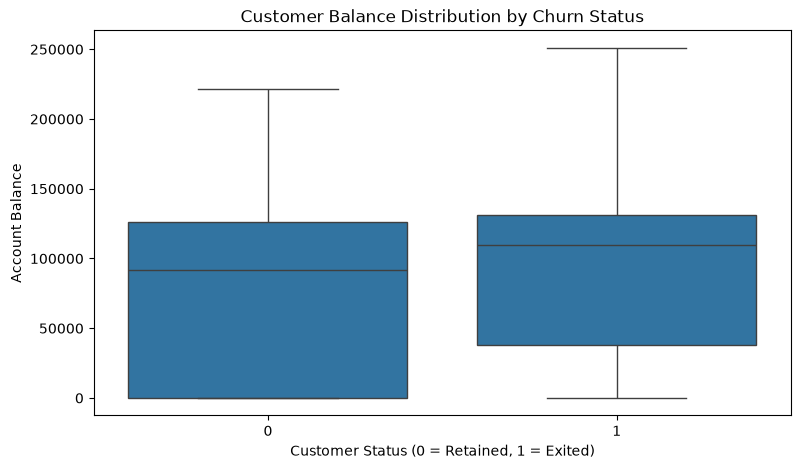

In [ ]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Exited",
    y="Balance"
)

plt.title("Customer Balance Distribution by Churn Status")
plt.xlabel("Customer Status (0 = Retained, 1 = Exited)")
plt.ylabel("Account Balance")

plt.show()


B. Salary distribution by churn

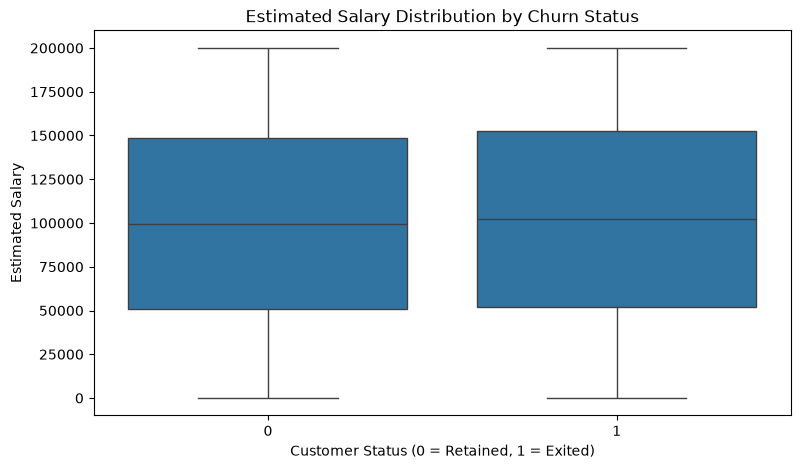

In [38]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Exited",
    y="EstimatedSalary"
)

plt.title("Estimated Salary Distribution by Churn Status")
plt.xlabel("Customer Status (0 = Retained, 1 = Exited)")
plt.ylabel("Estimated Salary")

plt.show()


# Analysis 6 — Age and churn

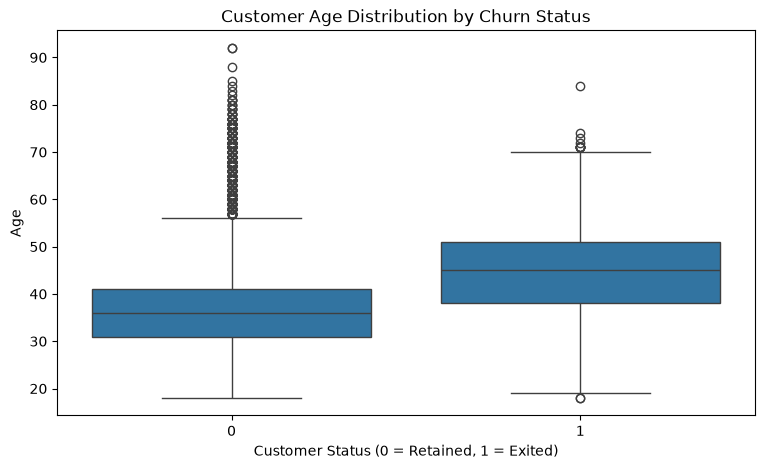

In [39]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Exited",
    y="Age"
)

plt.title("Customer Age Distribution by Churn Status")
plt.xlabel("Customer Status (0 = Retained, 1 = Exited)")
plt.ylabel("Age")

plt.show()


In [40]:

# Examine the number of customers in each product group
product_group_summary = df.groupby("NumOfProducts").agg(
    Total_Customers=("CustomerId", "count"),
    Exited_Customers=("Exited", "sum"),
    Retained_Customers=("Exited", lambda x: (x == 0).sum()),
    Churn_Rate=("Exited", "mean")
)

product_group_summary["Churn_Rate"] *= 100

product_group_summary


,Total_Customers,Exited_Customers,Retained_Customers,Churn_Rate
NumOfProducts,,,,
1,5084,1409,3675,27.714398
2,4590,348,4242,7.581699
3,266,220,46,82.706767
4,60,60,0,100.000000


In [41]:

# Compare customer churn across product count and activity status
product_activity_analysis = df.pivot_table(
    index="NumOfProducts",
    columns="IsActiveMember",
    values="Exited",
    aggfunc="mean"
) * 100

# Give activity columns readable names
product_activity_analysis.columns = ["Inactive", "Active"]

product_activity_analysis


,Inactive,Active
NumOfProducts,,
1,36.652122,18.923137
2,9.888060,5.560098
3,88.235294,75.221239
4,100.000000,100.000000



#  Exploratory Data Analysis Findings

## 1 Overall Customer Churn Distribution

The dataset contains 10,000 customers, of which 7,963 (79.63%) were retained and 2,037 (20.37%) exited.

The overall customer churn rate is 20.37%, indicating that approximately one in five customers left the bank.

## 2 Geography and Customer Churn

Germany recorded the highest churn rate at approximately 32.4%, followed by Spain at 16.7% and France at 16.2%.

This indicates geographical differences in customer retention patterns. Germany represents an important area for further investigation and targeted retention strategies.

## 3 Gender and Customer Churn

Female customers recorded an approximate churn rate of 25.1%, compared with 16.4% among male customers.

This indicates differences in observed churn patterns between gender groups. Further investigation is required to understand the underlying customer behaviour.

## 4 Customer Engagement and Churn

Inactive customers recorded an approximate churn rate of 26.9%, compared with 14.3% among active customers.

This suggests that customer activity is associated with retention. Inactive customers may require additional engagement initiatives to reduce potential churn.

## 5 Product Utilization and Customer Churn

The relationship between the number of bank products and customer churn revealed the following:

| Product Count | Customers | Exited | Retained | Churn Rate |
|---|---:|---:|---:|---:|
| 1 | 5,084 | 1,409 | 3,675 | 27.71% |
| 2 | 4,590 | 348 | 4,242 | 7.58% |
| 3 | 266 | 220 | 46 | 82.71% |
| 4 | 60 | 60 | 0 | 100.00% |

Customers holding two products demonstrated the lowest observed churn rate.

However, customers holding three and four products showed substantially higher churn rates. The smaller sample sizes of these groups should be considered when interpreting the results.

## 6 Product Utilization and Customer Engagement

A combined analysis of product count and customer activity revealed:

| Product Count | Inactive Churn (%) | Active Churn (%) |
|---|---:|---:|
| 1 | 36.65 | 18.92 |
| 2 | 9.89 | 5.56 |
| 3 | 88.24 | 75.22 |
| 4 | 100.00 | 100.00 |

Inactive customers showed higher churn rates than active customers across the first three product groups.

For customers holding four products, both activity groups recorded 100% churn.

These findings suggest that customer engagement and product utilization should be examined together when evaluating retention.

## 7 Financial Characteristics and Customer Churn

The account balance comparison showed that exited customers had a higher median balance than retained customers.

However, estimated salary distributions were broadly similar between retained and exited customers.

These observations suggest that financial characteristics alone may not adequately explain customer retention.

High-balance customers who are inactive require further investigation.

## 8 Age and Customer Churn

The age distribution analysis showed that exited customers generally had a higher median age than retained customers.

The median age was approximately 45 years for exited customers and 36 years for retained customers.

This suggests an association between customer age and churn behaviour.

## 9 Overall EDA Observations

The exploratory analysis identified several important patterns:

1. The overall churn rate is 20.37%.
2. Germany recorded the highest geographical churn rate.
3. Female customers showed a higher observed churn rate than male customers.
4. Inactive customers demonstrated higher churn than active customers.
5. Customers holding two products recorded the lowest observed churn rate.
6. Customers with three and four products showed unusually high churn rates.
7. Exited customers had higher median account balances.
8. Estimated salary distributions were broadly similar across churn groups.
9. Exited customers generally had a higher median age.

## 10 Business Implications

Based on the exploratory findings, the following areas require further investigation:

- Improve engagement initiatives for inactive customers.
- Investigate customer retention patterns in Germany.
- Examine why customers holding three and four products have unusually high churn rates.
- Identify high-balance customers who are inactive.
- Evaluate product adoption and relationship depth alongside customer activity.
- Develop targeted retention strategies based on customer behaviour.

## 11 Limitations

The analysis identifies associations and does not establish causal relationships.

Some customer segments, particularly those holding four products, contain relatively few observations. Their churn rates should therefore be interpreted cautiously.

Further segmentation and statistical analysis are required before making final business recommendations.
vvv


## 5. High-Value Disengaged Customer Analysis

This analysis identifies inactive customers with above-median account balances and examines their retention status.

In [44]:
median_balance = df["Balance"].median()

print("Median Balance:", median_balance)


Median Balance: 97198.54000000001


5.1 Identify high-balance inactive customers

In [46]:

high_balance_inactive = df[
    (df["Balance"] > median_balance) &
    (df["IsActiveMember"] == 0)
]

print("High-balance inactive customers:", len(high_balance_inactive))


High-balance inactive customers: 2456


5.2 Separate retained and exited customers

In [47]:

risk_status = high_balance_inactive["Exited"].value_counts()


risk_percentage = (
    high_balance_inactive["Exited"]
    .value_counts(normalize=True) * 100
)

risk_summary = pd.DataFrame({
    "Customer Count": risk_status,
    "Percentage": risk_percentage
})

risk_summary.index = ["Retained", "Exited"]

risk_summary


,Customer Count,Percentage
Retained,1662,67.67101
Exited,794,32.32899


5.3 Compare high-balance customers by activity and churn

In [49]:
balance_activity_analysis = df.pivot_table(
    index="IsActiveMember",
    columns="Exited",
    values="Balance",
    aggfunc="count"
)

balance_activity_analysis.index = ["Inactive", "Active"]
balance_activity_analysis.columns = ["Retained", "Exited"]

balance_activity_analysis


,Retained,Exited
Inactive,3547,1302
Active,4416,735


5.4 Compare average account balances across customer groups

In [ ]:
\
average_balance_analysis = df.groupby(
    ["IsActiveMember", "Exited"]
)["Balance"].mean().unstack()

average_balance_analysis.index = ["Inactive", "Active"]
average_balance_analysis.columns = ["Retained", "Exited"]

average_balance_analysis


,Retained,Exited
Inactive,72048.820578,90988.807081
Active,73304.717314,91320.636476


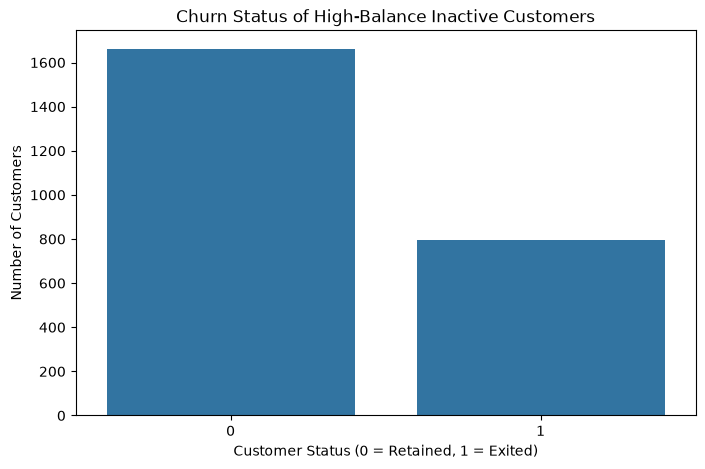

In [52]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=high_balance_inactive,
    x="Exited"
)

plt.title("Churn Status of High-Balance Inactive Customers")
plt.xlabel("Customer Status (0 = Retained, 1 = Exited)")
plt.ylabel("Number of Customers")

plt.show()



##  High-Value Disengaged Customer Findings

The median account balance was 97,198.54. Using this as the preliminary threshold, 2,456 customers were identified as having above-median balances and inactive membership.

- Retained customers: 1,662 (67.67%).
- Exited customers: 794 (32.33%).

Exited customers also showed higher average balances than retained customers across both activity groups.

### Business Observation

A considerable number of high-balance inactive customers remain with the bank and may be suitable targets for engagement-based retention initiatives.

Account balance and activity should be evaluated together when identifying potentially at-risk customers.

### Limitation

Above-median balance is a preliminary proxy for customer value, not a complete measure of customer profitability or wealth.


## 6. Customer Engagement Classification.

The objective is to divide customers into the four engagement categories specified in your Unified Mentor assignment.

6.1 Create customer segments

In [54]:

# Define conditions for each customer segment
conditions = [
    (df["IsActiveMember"] == 0) & (df["Balance"] > median_balance),

    (df["IsActiveMember"] == 1) & (df["NumOfProducts"] == 1),

    (df["IsActiveMember"] == 1) & (df["NumOfProducts"] > 1),

    (df["IsActiveMember"] == 0)
]

# Assign a segment to each customer
segments = [
    "Inactive High-Balance",
    "Active but Low-Product",
    "Active Engaged",
    "Inactive Disengaged"
]

df["Engagement_Segment"] = np.select(
    conditions,
    segments,
    default="Unclassified"
)

df["Engagement_Segment"].value_counts()


Engagement_Segment
Active Engaged            2588
Active but Low-Product    2563
Inactive High-Balance     2456
Inactive Disengaged       2393
Name: count, dtype: int64

6.2 Analyze churn by engagement segment

In [55]:

# Calculate customer count and churn rate by engagement segment
engagement_summary = df.groupby("Engagement_Segment").agg(
    Total_Customers=("CustomerId", "count"),
    Exited_Customers=("Exited", "sum"),
    Churn_Rate=("Exited", "mean")
)

# Convert churn rate into percentage
engagement_summary["Churn_Rate"] *= 100

engagement_summary.sort_values(
    by="Churn_Rate",
    ascending=False
)


,Total_Customers,Exited_Customers,Churn_Rate
Engagement_Segment,,,
Inactive High-Balance,2456,794,32.328990
Inactive Disengaged,2393,508,21.228583
Active but Low-Product,2563,485,18.923137
Active Engaged,2588,250,9.659969


6.3 Visualize customer segments

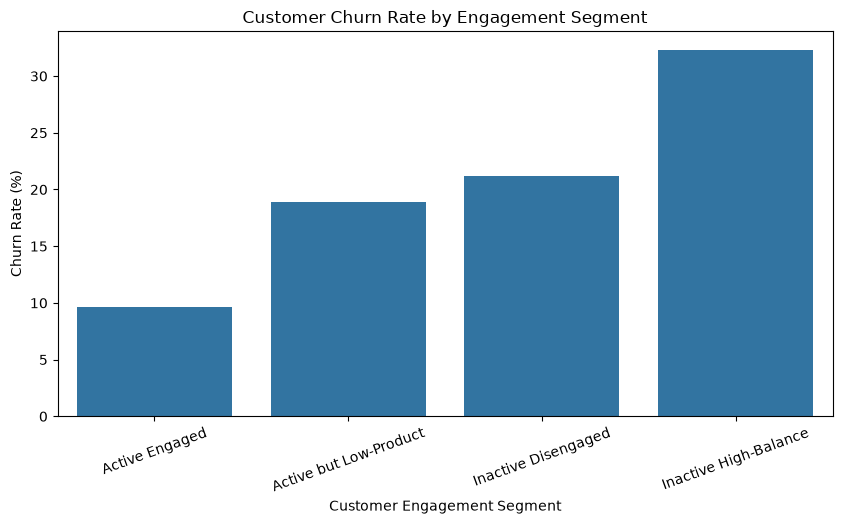

In [56]:

plt.figure(figsize=(10, 5))

sns.barplot(
    data=engagement_summary.reset_index(),
    x="Engagement_Segment",
    y="Churn_Rate"
)

plt.title("Customer Churn Rate by Engagement Segment")
plt.xlabel("Customer Engagement Segment")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20)

plt.show()


### 6.5 Document Your Findings

The engagement analysis identified the following important findings:

| Customer Segment | Churn Rate | Interpretation |
|---|---:|---|
| Inactive High-Balance | 32.33% | Highest churn risk; these customers need priority attention. |
| Inactive Disengaged | 21.23% | Churn is slightly above the overall rate. |
| Active but Low-Product | 18.92% | Opportunity to improve product adoption. |
| Active Engaged | 9.66% | Lowest churn rate and comparatively stronger retention. |

**Key Observations:**

- Inactive high-balance customers have the highest churn rate (32.33%).
- Inactive disengaged customers also show a relatively high churn rate (21.23%).
- Active but low-product customers may benefit from suitable additional product offerings.
- Active engaged customers have the lowest churn rate (9.66%).
- Customer activity and product adoption are associated with differences in churn rates.

**Conclusion:**

Customer engagement plays an important role in understanding retention patterns. The analysis suggests that retention efforts should prioritize inactive high-balance customers and encourage stronger engagement among inactive customers.